# Part 9: From our own phone recordings to UCI-style windows and features

**Goal:** test the final model on recordings from our own phones (Part 10). The model expects exactly what UCI gave it: 2.56 s windows at 50 Hz, turned into (some of) the 561 features, on the same [-1, 1] scale. This notebook builds that pipeline and checks it against UCI's own data.

**Data used:** the 21 training people only (`train/`). The 9 test people are untouched. No model is tuned here.

**The pipeline (same steps as UCI's `features_info.txt`):**
1. Load the phone CSV, convert units (acceleration to g, rotation to rad/s), sort the time stamps.
2. Put each sensor on an even time grid at its own rate, remove noise (median filter + 3rd-order Butterworth low-pass at 20 Hz), then **resample to 50 Hz**.
3. Split acceleration into **gravity** (Butterworth low-pass at 0.3 Hz) and **body** motion (the rest).
4. Cut **128-sample windows with 50% overlap** (2.56 s, a new window every 1.28 s).
5. Compute the features, and map them onto UCI's [-1, 1] scale.

In [1]:
import os
import time
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, lfilter, lfilter_zi, medfilt
from sklearn.model_selection import PredefinedSplit, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from config import SEED, DATA

FS = 50                  # UCI sampling rate (Hz)
WINDOW, STEP = 128, 64   # 2.56 s windows, 50% overlap
G = 9.80665              # 1 g in m/s² (the value UCI uses)

feature_names = pd.read_csv(DATA + "/features.txt", sep=r"\s+", header=None)[1].tolist()
activity = {1: "walking", 2: "upstairs", 3: "downstairs", 4: "sitting", 5: "standing", 6: "lying"}
print(len(feature_names), "UCI feature names")

561 UCI feature names


## Step 1: signal processing functions
- **`even_grid`**: phones do not record at perfectly even times. We interpolate each channel onto an even time grid (linear interpolation between neighbouring readings).
- **`remove_noise`**: a median filter (3 readings wide) removes single spikes, then a 3rd-order Butterworth low-pass at 20 Hz removes fast jitter. This is done at the phone's own rate, **before** going down to 50 Hz, so it also prevents aliasing (fast vibrations folding into slower frequencies when we keep fewer samples).
- **`split_gravity`**: a 3rd-order Butterworth low-pass at 0.3 Hz keeps only the slow part = **gravity** (orientation). **Body** = total − gravity. We use the causal filter `lfilter` (it only looks at the past, like a phone in real time); Cell 9 compares it with the zero-delay `filtfilt`.
- **`make_windows`**: cuts a long signal into 128-sample windows, starting every 64 samples.

In [2]:
def even_grid(t, values, rate):
    """Interpolate readings taken at times t (s) onto an even grid with the given rate (Hz)."""
    grid = np.arange(t[0], t[-1], 1 / rate)
    return grid, np.column_stack([np.interp(grid, t, values[:, i]) for i in range(values.shape[1])])


def remove_noise(values, rate):
    """Median filter (3 readings) + 3rd-order Butterworth low-pass at 20 Hz, applied per channel."""
    smooth = np.column_stack([medfilt(values[:, i], 3) for i in range(values.shape[1])])
    b, a = butter(3, 20 / (rate / 2), "low")
    return filtfilt(b, a, smooth, axis=0)


def split_gravity(total_acc, causal=True):
    """3rd-order Butterworth low-pass at 0.3 Hz (signal at 50 Hz). Returns (body, gravity)."""
    b, a = butter(3, 0.3 / (FS / 2), "low")
    if causal:   # start the filter at the first reading, so it does not have to climb up from 0
        zi = lfilter_zi(b, a)[:, None] * total_acc[0]
        gravity = lfilter(b, a, total_acc, axis=0, zi=zi)[0]
    else:
        gravity = filtfilt(b, a, total_acc, axis=0)
    return total_acc - gravity, gravity


def make_windows(signal):
    """(n_samples, channels) -> (n_windows, 128, channels), 50% overlap."""
    starts = range(0, len(signal) - WINDOW + 1, STEP)
    return np.stack([signal[s:s + WINDOW] for s in starts]) if len(signal) >= WINDOW else np.empty((0, WINDOW, signal.shape[1]))

## Step 2: computing the features
We compute **all 561 features in UCI's order**, then check below which ones really match UCI's values. While checking, we found how UCI defines some of them (these details are not in `features_info.txt`):
- `mad()` is the **mean** absolute deviation from the mean (not the median version).
- Frequency features use the FFT size |FFT| of bins **1 to 64**: the 0 Hz bin (the window's average) is **left out**. With it included, `maxInds` of the magnitude signals would always be 0.
- Jerk = change between neighbouring readings × 50 (per second); `bandsEnergy` = sum of |FFT|² over a range of those 64 bins.
- `arCoeff()` = 4 autoregression coefficients from Burg's method. Ours come out with the **opposite sign** to UCI's, which does not matter, because the [-1, 1] mapping (Step 3) can flip the sign.
- `entropy()`: we tried 6 definitions (histograms, normalised energy, spectral entropy) and none matched, so the entropy features are **left out** (see the validation).

In [3]:
BANDS = [(1, 8), (9, 16), (17, 24), (25, 32), (33, 40), (41, 48), (49, 56), (57, 64),
         (1, 16), (17, 32), (33, 48), (49, 64), (1, 24), (25, 48)]


def entropy(s, bins=10):
    """Histogram entropy per window (our best guess; it does NOT match UCI, so it is excluded later)."""
    out = np.empty(len(s))
    for i, row in enumerate(s):
        h, _ = np.histogram(row, bins=bins)
        p = h[h > 0] / h.sum()
        out[i] = -(p * np.log2(p)).sum()
    return out


def burg(s, order=4):
    """Autoregression coefficients by Burg's method, for every window at once. s: (n, length)."""
    f, b = s.copy(), s.copy()
    a = np.ones((len(s), 1))
    for m in range(order):
        ef, eb = f[:, m + 1:], b[:, m:-1]
        k = -2 * (ef * eb).sum(1) / ((ef ** 2).sum(1) + (eb ** 2).sum(1) + 1e-12)
        a = np.hstack([a, np.zeros((len(s), 1))])
        a = a + k[:, None] * a[:, ::-1]
        f[:, m + 1:], b[:, m + 1:] = ef + k[:, None] * eb, eb + k[:, None] * ef
    return -a[:, 1:]


def basic_stats(s):
    """mean, std, mad, max, min, energy, iqr, entropy of each row of s (n, length)."""
    q75, q25 = np.percentile(s, [75, 25], axis=1)
    return {"mean": s.mean(1), "std": s.std(1), "mad": np.abs(s - s.mean(1, keepdims=True)).mean(1),
            "max": s.max(1), "min": s.min(1), "energy": (s ** 2).mean(1), "iqr": q75 - q25, "entropy": entropy(s)}


def spectrum(s):
    """|FFT| bins 1..64 of each 128-sample row (the 0 Hz bin is left out, as UCI does)."""
    return np.abs(np.fft.fft(s, axis=1))[:, 1:65]


def freq_stats(F):
    st = basic_stats(F)
    bins = np.arange(1, 65)
    centred = F - F.mean(1, keepdims=True)
    st["maxInds"] = F.argmax(1).astype(float)
    st["meanFreq"] = (bins * F).sum(1) / F.sum(1)
    st["skewness"] = (centred ** 3).mean(1) / F.std(1) ** 3
    st["kurtosis"] = (centred ** 4).mean(1) / F.std(1) ** 4 - 3
    return st


def angle(u, v):
    cos = (u * v).sum(1) / (np.linalg.norm(u, axis=1) * np.linalg.norm(v, axis=1))
    return np.arccos(np.clip(cos, -1, 1))


def compute_features(body, gravity, gyro):
    """body, gravity, gyro: (n_windows, 128, 3) in g, g and rad/s. Returns (n_windows, 561) in UCI's column order."""
    cols = []
    jerk = np.diff(body, axis=1) * FS
    gyro_jerk = np.diff(gyro, axis=1) * FS

    for S in [body, gravity, jerk, gyro, gyro_jerk]:                       # t...-XYZ signals
        st = [basic_stats(S[:, :, i]) for i in range(3)]
        for name in ["mean", "std", "mad", "max", "min"]:
            cols += [st[i][name] for i in range(3)]
        cols.append(np.abs(S).sum(2).mean(1))                                # sma
        for name in ["energy", "iqr", "entropy"]:
            cols += [st[i][name] for i in range(3)]
        for i in range(3):
            cols += list(burg(S[:, :, i]).T)                                 # arCoeff 1-4
        for i, j in [(0, 1), (0, 2), (1, 2)]:                                # correlation
            x, y = S[:, :, i] - S[:, :, i].mean(1, keepdims=True), S[:, :, j] - S[:, :, j].mean(1, keepdims=True)
            cols.append((x * y).sum(1) / np.sqrt((x ** 2).sum(1) * (y ** 2).sum(1)))

    for S in [body, gravity, jerk, gyro, gyro_jerk]:                       # t...Mag signals
        m = np.linalg.norm(S, axis=2)
        st = basic_stats(m)
        cols += [st[name] for name in ["mean", "std", "mad", "max", "min"]]
        cols.append(np.abs(m).mean(1))                                       # sma
        cols += [st[name] for name in ["energy", "iqr", "entropy"]]
        cols += list(burg(m).T)

    for S in [body, jerk, gyro]:                                           # f...-XYZ signals
        F = [spectrum(S[:, :, i]) for i in range(3)]
        st = [freq_stats(Fi) for Fi in F]
        for name in ["mean", "std", "mad", "max", "min"]:
            cols += [st[i][name] for i in range(3)]
        cols.append(sum(F).mean(1))                                          # sma
        for name in ["energy", "iqr", "entropy", "maxInds", "meanFreq"]:
            cols += [st[i][name] for i in range(3)]
        for i in range(3):
            cols += [st[i]["skewness"], st[i]["kurtosis"]]
        for i in range(3):
            cols += [(F[i][:, lo - 1:hi] ** 2).sum(1) for lo, hi in BANDS]

    for S in [body, jerk, gyro, gyro_jerk]:                                # f...Mag signals
        F = spectrum(np.linalg.norm(S, axis=2))
        st = freq_stats(F)
        cols += [st[name] for name in ["mean", "std", "mad", "max", "min"]]
        cols.append(F.mean(1))
        cols += [st[name] for name in ["energy", "iqr", "entropy", "maxInds", "meanFreq", "skewness", "kurtosis"]]

    g_mean = gravity.mean(1)
    for S in [body, jerk, gyro, gyro_jerk]:
        cols.append(angle(S.mean(1), g_mean))
    for i in range(3):
        axis = np.zeros((len(g_mean), 3))
        axis[:, i] = 1
        cols.append(angle(axis, g_mean))

    return np.column_stack(cols)

## Check 1: recompute the features from UCI's own windows
UCI also gives the **raw windows** for every training row (`train/Inertial Signals/`): total acceleration, body acceleration (gravity already removed) and gyroscope, 128 readings each. Gravity = total − body. We feed them into `compute_features` and compare each recomputed feature with UCI's provided column over all 7,352 training windows.

**How we compare despite the scaling:** UCI rescaled every feature to [-1, 1] with a straight-line (min-max) mapping, `provided = a × raw + b`. A straight-line mapping does not change the **correlation**, so |r| close to 1 means "same feature, just rescaled". We group the features by how well they match: **reproduced** (|r| ≥ 0.99), **approximate** (0.9 ≤ |r| < 0.99), **not reproduced** (|r| < 0.9). Takes about 30 seconds.

In [4]:
X = pd.read_csv(DATA + "/train/X_train.txt", sep=r"\s+", header=None).values
y = np.loadtxt(DATA + "/train/y_train.txt", dtype=int)
groups = np.loadtxt(DATA + "/train/subject_train.txt", dtype=int)

def load_channel(name):
    return np.loadtxt(DATA + "/train/Inertial Signals/" + name + "_train.txt")

total = np.stack([load_channel("total_acc_" + a) for a in "xyz"], axis=2)
body = np.stack([load_channel("body_acc_" + a) for a in "xyz"], axis=2)
gyro = np.stack([load_channel("body_gyro_" + a) for a in "xyz"], axis=2)
gravity = total - body

start = time.time()
ours = compute_features(body, gravity, gyro)
print("computed:", ours.shape, "in", round(time.time() - start, 1), "s")

r = np.array([np.corrcoef(ours[:, j], X[:, j])[0, 1] if ours[:, j].std() > 0 else 0 for j in range(561)])
check = pd.DataFrame({"name": feature_names, "abs_r": np.abs(r)})
check["statistic"] = check["name"].str.extract(r"-([A-Za-z]+)")[0].fillna("angle")
check["match"] = pd.cut(check["abs_r"], [-0.01, 0.9, 0.99, 1.01], labels=["not reproduced", "approximate", "reproduced"])
print(check["match"].value_counts().to_string())

computed: (7352, 561) in 18.7 s
match
reproduced        451
not reproduced     70
approximate        40


In [5]:
table = check.groupby("statistic").agg(features=("abs_r", "size"), median_abs_r=("abs_r", "median"),
                                      reproduced=("match", lambda m: (m == "reproduced").sum()))
print(table.sort_values("median_abs_r", ascending=False).round(3).to_string())

print()
print("not reproduced, grouped:")
bad = check[check["match"] == "not reproduced"]
print("  entropy features:", bad["name"].str.contains("entropy").sum())
print("  tGravityAccMag features:", bad["name"].str.startswith("tGravityAccMag").sum())
print("  tGravityAcc-arCoeff features:", bad["name"].str.startswith("tGravityAcc-arCoeff").sum())
print("  others:", bad[~bad["name"].str.contains("entropy|tGravityAccMag|tGravityAcc-arCoeff")]["name"].tolist())

# UCI's tGravityAccMag columns: are they really copies of tBodyAccMag?
body_mag = [j for j, n in enumerate(feature_names) if n.startswith("tBodyAccMag")]
grav_mag = [j for j, n in enumerate(feature_names) if n.startswith("tGravityAccMag")]
same = [np.corrcoef(X[:, a], X[:, b])[0, 1] for a, b in zip(body_mag, grav_mag)]
print()
print("UCI's tGravityAccMag vs tBodyAccMag columns, r =", np.round(same, 4).min(), "to", np.round(same, 4).max())

             features  median_abs_r  reproduced
statistic                                      
maxInds            13         1.000           8
energy             33         1.000          32
mean               33         1.000          26
angle               7         1.000           5
sma                17         1.000          16
kurtosis           13         1.000           8
skewness           13         1.000           8
std                33         1.000          32
mad                33         1.000          32
max                33         1.000          32
meanFreq           13         1.000           8
bandsEnergy       126         1.000         111
min                33         1.000          27
correlation        15         1.000          15
iqr                33         1.000          27
arCoeff            80         0.996          64
entropy            33         0.124           0

not reproduced, grouped:
  entropy features: 33
  tGravityAccMag features: 13
  tGravit

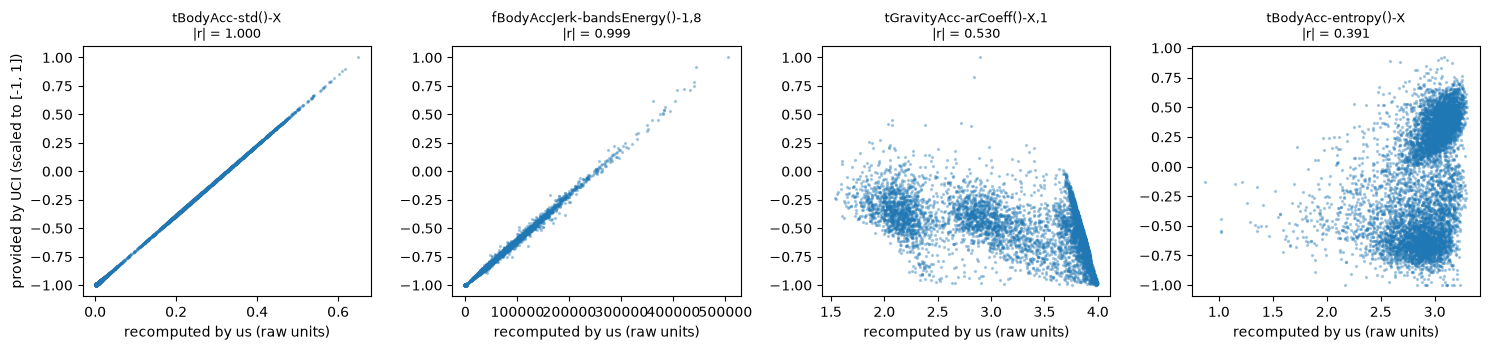

In [6]:
examples = ["tBodyAcc-std()-X", "fBodyAccJerk-bandsEnergy()-1,8", "tGravityAcc-arCoeff()-X,1", "tBodyAcc-entropy()-X"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, name in zip(axes, examples):
    j = feature_names.index(name)
    ax.scatter(ours[:, j], X[:, j], s=2, alpha=0.3)
    ax.set_title(f"{name}\n|r| = {abs(r[j]):.3f}", fontsize=9)
    ax.set_xlabel("recomputed by us (raw units)")
axes[0].set_ylabel("provided by UCI (scaled to [-1, 1])")
plt.tight_layout()
plt.show()

## Step 3: putting our features on UCI's [-1, 1] scale
The model was trained on UCI's **scaled** values, so a phone feature must be put on the same scale before it goes into the model. UCI's mapping is a straight line per feature, `provided = a × raw + b`, but they did not publish a and b (and they probably used all 30 people, test people included, to find the min and max).

So we **learn a and b for each feature from the 21 training people**: a least-squares straight-line fit of UCI's provided value on our recomputed value. For a reproduced feature the fit is almost perfect (R² = r² ≥ 0.98). The same a and b are then applied to every phone window. Phone values may land slightly outside [-1, 1]; that is fine, and we report how often it happens.

In [7]:
slope = np.zeros(561)
intercept = np.zeros(561)
for j in range(561):
    if ours[:, j].std() > 0:
        slope[j], intercept[j] = np.polyfit(ours[:, j], X[:, j], 1)


def to_uci_scale(raw_features):
    return raw_features * slope + intercept


scaled = to_uci_scale(ours)
good = (check["match"] == "reproduced").values
error = np.abs(scaled - X)
print("provided values range:", X.min(), "to", X.max())
print("reproduced features: median |error| after scaling =", round(np.median(error[:, good]), 4),
      "| 99th percentile =", round(np.percentile(error[:, good], 99), 4), "(on a scale of width 2)")
print("arCoeff slopes are negative (sign flip):", (slope[check["statistic"] == "arCoeff"] < 0).mean().round(2))

provided values range: -1.0 to 1.0
reproduced features: median |error| after scaling = 0.0 | 99th percentile = 0.0339 (on a scale of width 2)
arCoeff slopes are negative (sign flip): 1.0


## Check 2: does our 0.3 Hz filter give UCI's gravity?
UCI's windows overlap by 50%, so consecutive windows from one bout can be glued back into one **continuous** recording (keep the first window, then add the last 64 readings of each next window). We apply our gravity filter to the glued total acceleration and compare with UCI's gravity (total − body). The first and last 128 readings of each bout are skipped, because every filter needs a moment to settle at the start.

In [8]:
continues = np.isclose(total[:-1, 64:, 0], total[1:, :64, 0]).all(axis=1)
bout_starts = np.r_[0, np.where(~continues)[0] + 1]
bout_ends = np.r_[bout_starts[1:], len(total)]

errors = {"lfilter (causal)": [], "filtfilt (zero delay)": []}
for s, e in zip(bout_starts, bout_ends):
    if e - s < 6:
        continue
    glued_total = np.concatenate([total[s]] + [total[k, 64:] for k in range(s + 1, e)])
    glued_gravity = np.concatenate([gravity[s]] + [gravity[k, 64:] for k in range(s + 1, e)])
    middle = slice(128, len(glued_total) - 128)
    for label, causal in [("lfilter (causal)", True), ("filtfilt (zero delay)", False)]:
        _, our_gravity = split_gravity(glued_total, causal=causal)
        errors[label].append(np.sqrt(((our_gravity[middle] - glued_gravity[middle]) ** 2).mean()))

print("bouts used:", len(errors["lfilter (causal)"]))
for label, v in errors.items():
    print(f"{label:22s} gravity error (RMS, g): median {np.median(v):.4f}, 90th percentile {np.percentile(v, 90):.4f}")
print("for scale, typical body acceleration (RMS, g):", round(np.sqrt((body ** 2).mean()), 4))

bouts used: 590
lfilter (causal)       gravity error (RMS, g): median 0.0022, 90th percentile 0.0053
filtfilt (zero delay)  gravity error (RMS, g): median 0.0097, 90th percentile 0.0211
for scale, typical body acceleration (RMS, g): 0.1465


## Check 3: is the reproducible subset good enough for a model?
If Part 10 can only use the reproduced features, how much does that cost? Logistic regression (scaler + `LogisticRegression`, C = 1 as in Part 4), saved folds, four inputs:
1. all 561 provided features (Part 4's setup);
2. the **provided** values of the reproduced features only;
3. **our recomputed** values of the reproduced features, put on UCI's scale (this is what the phone pipeline will deliver);
4. our recomputed values of the reproduced **and** approximate features.

Inputs 3 and 4 use a and b fitted on all 21 training people; that is a mild shortcut (a straight-line rescaling before a `StandardScaler` changes almost nothing). Runs in about a minute.

In [9]:
folds_table = pd.read_csv("results/folds.csv", index_col="person")["fold"]
saved_folds = PredefinedSplit(folds_table.loc[groups].values)
usable = (check["match"] != "not reproduced").values

inputs = {
    "all 561 provided": X,
    f"provided, reproduced only ({good.sum()})": X[:, good],
    f"ours, reproduced only ({good.sum()})": scaled[:, good],
    f"ours, reproduced + approximate ({usable.sum()})": scaled[:, usable],
}
for label, data in inputs.items():
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    f1s = cross_val_score(model, data, y, cv=saved_folds, scoring="f1_macro", n_jobs=-1)
    print(f"{label:42s} macro-F1 {f1s.mean():.3f} ± {f1s.std(ddof=1):.3f}")

all 561 provided                           macro-F1 0.933 ± 0.036


provided, reproduced only (451)            macro-F1 0.931 ± 0.036


ours, reproduced only (451)                macro-F1 0.931 ± 0.037


ours, reproduced + approximate (491)       macro-F1 0.929 ± 0.037


## Step 4: loading phone recordings
### How to record (please follow this, it matters for the model)
- **Phone position:** at the **waist**, in a belt pouch or clipped firmly to the waistband (not loose in a pocket), at the **same place and in the same orientation every time**. UCI's phone was at the waist with its **x axis pointing up** when standing.
- **Before the first recording:** record 20 s of standing still. We check the orientation with it (Cell 15): standing should give gravity mostly on x, like UCI's standing windows. If not, we fix it with `axis_map` in the loader.
- **Sensors:** accelerometer **including gravity** (in phyphox: "Acceleration *with* g") **and** gyroscope, recorded **at the same time**, at 50 Hz or faster.
- **Activities:** all 6 (walking, upstairs, downstairs, sitting, standing, lying), **1–2 minutes each, one file per activity**. Start the recording, get into position, and stay in the activity until you stop; we cut the first and last 5 s (pressing buttons, putting the phone away).
- **Write down** for each file: person, activity, phone model, where the phone was worn, and anything unusual.

### Where to put the files
```
data/phone/<person>/<activity>.csv                      one file with both sensors, or
data/phone/<person>/<activity>_acc.csv  and  <activity>_gyro.csv    one file per sensor
```
`<person>` = e.g. `lakshika`, `bhavya`; `<activity>` = one of `walking, upstairs, downstairs, sitting, standing, lying`.

### What the CSV must look like
A **time column in seconds** and three columns per sensor, for example the phyphox export:
```
"Time (s)","Acceleration x (m/s^2)","Acceleration y (m/s^2)","Acceleration z (m/s^2)"
"Time (s)","Gyroscope x (rad/s)","Gyroscope y (rad/s)","Gyroscope z (rad/s)"
```
The loader finds the columns by name (time / acc or acceleration or gF / gyro), converts **m/s² to g** (÷ 9.80665) if the header says m/s² or the readings at rest are around 9.8, and keeps gyroscope values in rad/s. If your app exports a different layout, send me one file and I will adapt the loader.

In [10]:
ACTIVITY_CODE = {name: code for code, name in activity.items()}


def read_sensor_csv(path, kind):
    """Read one CSV; return times (s) and an (n, 3) array for 'acc' (in g) or 'gyro' (in rad/s)."""
    table = pd.read_csv(path)
    lower = {c: c.lower() for c in table.columns}
    time_col = [c for c in table.columns if "time" in lower[c]][0]
    if kind == "acc":
        cols = [c for c in table.columns if any(k in lower[c] for k in ["acc", "gf"]) and "time" not in lower[c]][:3]
    else:
        cols = [c for c in table.columns if any(k in lower[c] for k in ["gyro", "rad/s", "w"]) and "time" not in lower[c]
                and not any(k in lower[c] for k in ["acc", "gf"])][:3]
    if len(cols) != 3:
        raise ValueError(f"{path}: could not find 3 {kind} columns in {list(table.columns)}")
    table = table[[time_col] + cols].dropna().sort_values(time_col).drop_duplicates(time_col)
    t, values = table[time_col].to_numpy(float), table[cols].to_numpy(float)
    if kind == "acc" and ("m/s" in " ".join(lower[c] for c in cols) or np.median(np.linalg.norm(values, axis=1)) > 5):
        values = values / G
    gaps = np.diff(t)
    if gaps.max() > 0.1:
        print(f"  warning: {os.path.basename(path)} has a gap of {gaps.max():.2f} s in the time stamps")
    return t, values


def load_recording(folder, activity_name, axis_map=(0, 1, 2), axis_sign=(1, 1, 1), trim=5.0, causal=True):
    """One activity recording -> (body, gravity, gyro) windows of shape (n, 128, 3), like UCI's Inertial Signals."""
    single = os.path.join(folder, activity_name + ".csv")
    acc_path = single if os.path.exists(single) else os.path.join(folder, activity_name + "_acc.csv")
    gyro_path = single if os.path.exists(single) else os.path.join(folder, activity_name + "_gyro.csv")
    t_acc, acc = read_sensor_csv(acc_path, "acc")
    t_gyro, gyro = read_sensor_csv(gyro_path, "gyro")

    smooth = {}
    for name, (t, values) in {"acc": (t_acc, acc), "gyro": (t_gyro, gyro)}.items():
        rate = 1 / np.median(np.diff(t))
        if rate < 45:
            print(f"  warning: {name} recorded at only {rate:.0f} Hz; UCI used 50 Hz")
        grid, even = even_grid(t, values, rate)
        smooth[name] = (grid, remove_noise(even, rate) if rate > 40 else even)

    start = max(smooth["acc"][0][0], smooth["gyro"][0][0])
    end = min(smooth["acc"][0][-1], smooth["gyro"][0][-1])
    common = np.arange(start, end, 1 / FS)
    at_50 = {}
    for name, (grid, values) in smooth.items():
        values = values[:, list(axis_map)] * np.array(axis_sign)
        at_50[name] = np.column_stack([np.interp(common, grid, values[:, i]) for i in range(3)])

    body_acc, grav = split_gravity(at_50["acc"], causal=causal)   # filter the whole recording first ...
    keep = (common >= start + trim) & (common <= end - trim)        # ... then cut the first and last seconds
    b, g, w = (make_windows(s[keep]) for s in (body_acc, grav, at_50["gyro"]))
    return b, g, w


def load_person(folder, **options):
    """All activity files of one person -> UCI-scaled features (n, 561), labels, and the raw windows."""
    features, labels = [], []
    for name, code in ACTIVITY_CODE.items():
        if not any(os.path.exists(os.path.join(folder, name + suffix)) for suffix in [".csv", "_acc.csv"]):
            continue
        b, g, w = load_recording(folder, name, **options)
        features.append(to_uci_scale(compute_features(b, g, w)))
        labels.append(np.full(len(b), code))
        print(f"  {name:10s} {len(b):4d} windows")
    return np.vstack(features), np.concatenate(labels)

## Check 4: test the loader on a fake recording
We do not have phone recordings yet. To test the loader end to end, we turn one UCI walking bout and one standing bout (training people) back into a "phone recording": glue the windows together, convert to m/s², put it on **uneven time stamps at about 100 Hz** (like a real phone), and save it in phyphox format to a temporary folder (outside the repo). Then we run it through the pipeline and compare the gravity direction and some features with UCI's windows of the same bouts.

In [11]:
rng = np.random.default_rng(SEED)
fake_folder = tempfile.mkdtemp()

def write_fake(code, name):
    s, e = [(s, e) for s, e in zip(bout_starts, bout_ends) if y[s] == code and e - s >= 20][0]
    glued_acc = np.concatenate([total[s]] + [total[k, 64:] for k in range(s + 1, e)])
    glued_gyro = np.concatenate([gyro[s]] + [gyro[k, 64:] for k in range(s + 1, e)])
    t50 = np.arange(len(glued_acc)) / FS
    t_phone = np.sort(rng.uniform(0, t50[-1], int(t50[-1] * 100)))          # uneven, about 100 Hz
    acc = np.column_stack([np.interp(t_phone, t50, glued_acc[:, i]) for i in range(3)]) * G
    rot = np.column_stack([np.interp(t_phone, t50, glued_gyro[:, i]) for i in range(3)])
    pd.DataFrame({"Time (s)": t_phone, **{f"Acceleration {a} (m/s^2)": acc[:, i] for i, a in enumerate("xyz")}}).to_csv(
        os.path.join(fake_folder, name + "_acc.csv"), index=False)
    pd.DataFrame({"Time (s)": t_phone, **{f"Gyroscope {a} (rad/s)": rot[:, i] for i, a in enumerate("xyz")}}).to_csv(
        os.path.join(fake_folder, name + "_gyro.csv"), index=False)
    return s, e

bouts = {"walking": write_fake(1, "walking"), "standing": write_fake(5, "standing")}
print("fake files:", sorted(os.listdir(fake_folder)))

fake_X, fake_y = load_person(fake_folder)
print("features:", fake_X.shape, "| labels:", np.unique(fake_y))
print("share of feature values outside [-1, 1]:", round(np.mean(np.abs(fake_X[:, good]) > 1), 3))

for name, code in [("walking", 1), ("standing", 5)]:
    s, e = bouts[name]
    for feature in ["tGravityAcc-mean()-X", "tBodyAcc-std()-X", "fBodyAcc-meanFreq()-X"]:
        j = feature_names.index(feature)
        print(f"  {name:8s} {feature:24s} phone pipeline {fake_X[fake_y == code, j].mean():+.3f}   UCI windows {X[s:e, j].mean():+.3f}")

fake files: ['standing_acc.csv', 'standing_gyro.csv', 'walking_acc.csv', 'walking_gyro.csv']


  walking      13 windows


  standing     12 windows
features: (25, 561) | labels: [1 5]
share of feature values outside [-1, 1]: 0.056
  walking  tGravityAcc-mean()-X     phone pipeline +0.964   UCI windows +0.964
  walking  tBodyAcc-std()-X         phone pipeline -0.655   UCI windows -0.630
  walking  fBodyAcc-meanFreq()-X    phone pipeline -0.565   UCI windows -0.399
  standing tGravityAcc-mean()-X     phone pipeline +0.945   UCI windows +0.946
  standing tBodyAcc-std()-X         phone pipeline -0.999   UCI windows -0.997
  standing fBodyAcc-meanFreq()-X    phone pipeline -0.321   UCI windows +0.037


## Check 5: orientation of the phone
The model learned "gravity mostly on x = upright". If our phone is worn turned, the same posture gives different numbers. This function compares the average gravity direction of our standing windows with UCI's standing windows (training people). If the axes are swapped or flipped, pass `axis_map` / `axis_sign` to `load_person`, e.g. `axis_map=(1, 0, 2), axis_sign=(1, -1, 1)` swaps x and y and flips the new y.

In [12]:
uci_standing_gravity = gravity[y == 5].mean(axis=(0, 1))


def check_orientation(features, labels):
    cols = [feature_names.index(f"tGravityAcc-mean()-{a}") for a in "XYZ"]
    ours_standing = features[labels == 5][:, cols].mean(0)
    uci_standing = X[y == 5][:, cols].mean(0)
    print("standing gravity (UCI scale)  X, Y, Z")
    print("  our recording:", np.round(ours_standing, 2))
    print("  UCI training: ", np.round(uci_standing, 2))
    print("  UCI standing gravity in g:", np.round(uci_standing_gravity, 2))

check_orientation(fake_X, fake_y)

standing gravity (UCI scale)  X, Y, Z
  our recording: [ 0.95 -0.19 -0.17]
  UCI training:  [ 0.94 -0.18 -0.03]
  UCI standing gravity in g: [ 1.   -0.16 -0.03]


# Part 9 summary: the phone pipeline

**Data used:** the 21 training people only (their raw windows and provided features). No test people, no phone recordings yet.

## What the pipeline does
phone CSV → units to g and rad/s → even time grid → median filter + 20 Hz Butterworth → **50 Hz** → gravity / body split (**0.3 Hz Butterworth, causal**) → **128-sample windows, 50% overlap** → 561 features in UCI's order → **UCI's [-1, 1] scale** (a straight line per feature, learned from the training people).

## What the checks showed
**Check 1: features recomputed from UCI's raw windows** (Cells 7–9, about 1 minute):

| Match with UCI's provided values | Features |
|---|---|
| **reproduced** (\|r\| ≥ 0.99) | **451** |
| approximate (0.9 ≤ \|r\| < 0.99) | 40 |
| not reproduced (\|r\| < 0.9) | 70 |

Things we had to work out, because `features_info.txt` does not say them: `mad()` is the **mean** absolute deviation; the frequency features **skip the 0 Hz bin** (FFT bins 1–64); our `arCoeff` comes out with the opposite sign (harmless).

**The 70 features we cannot reproduce, and why:**
- **33 `entropy()` features:** UCI does not define its entropy, and none of the 6 definitions we tried matched (best |r| ≈ 0.5).
- **13 `tGravityAccMag` features:** in UCI's file these columns are **exact copies** of `tBodyAccMag` (r = 1.0), probably a slip in the original processing. Ours are the real gravity magnitude, so they differ.
- **12 `tGravityAcc-arCoeff()` features:** gravity is almost constant within a window, so these coefficients describe tiny leftovers and react strongly to small processing differences.
- **12 jerk-spectrum features** (`fBodyAccJerk` min, maxInds, bandsEnergy 57–64, and the min/maxInds of the two jerk magnitudes): they depend on the highest frequencies, where small differences in how the jerk is computed show up most.

**Scaling (Cell 11):** after the straight-line mapping, the reproduced features are within 0.034 of UCI's values for 99% of windows (on a scale of width 2). All arCoeff slopes come out negative, confirming the sign flip.

**Check 2: the gravity filter (Cell 13).** On 590 rebuilt bouts, our causal 0.3 Hz filter gives UCI's gravity to within **0.0022 g** (median RMS error), much better than the zero-delay version (0.0097 g). So UCI most likely used a causal filter, and so do we. For scale: body motion is about 0.15 g.

**Check 3: is the subset enough? (Cell 15, logistic regression, saved folds)**

| Inputs | macro-F1 |
|---|---|
| all 561 provided features | 0.933 ± 0.036 |
| provided values, 451 reproduced features | 0.931 ± 0.036 |
| **our recomputed values, 451 reproduced features** | **0.931 ± 0.037** |
| our recomputed values, reproduced + approximate (491) | 0.929 ± 0.037 |

Dropping the 110 unreliable features costs almost nothing (0.002), and our own recomputed features work as well as UCI's. **Plan for Part 10: retrain the final model type on the 451 reproduced features** (training people only), because the phone cannot deliver the other 110 reliably.

**Check 4: the loader on a fake phyphox recording** (one walking and one standing bout, uneven ~100 Hz, m/s²). The loader read, converted, filtered, resampled and windowed it: 13 + 12 windows. Gravity matches UCI's windows of the same bouts (walking 0.964 vs 0.964; standing 0.945 vs 0.946), and so does movement size (`tBodyAcc-std()-X`: −0.655 vs −0.630). **But** `fBodyAcc-meanFreq()-X` of the standing bout differs a lot (−0.321 vs +0.037): when a person is still, the spectrum is mostly sensor noise, and its "shape" changes with any extra filtering. 5.6% of the fake windows' feature values fall outside [-1, 1]. Expect these "noise-shape" features to be the least reliable on real phones.

**Check 5: orientation.** The fake standing recording gives gravity (UCI scale) X, Y, Z = 0.95, −0.19, −0.17 vs UCI's 0.94, −0.18, −0.03, so the check works. For real recordings, this is where we find out whether the phone was worn the same way.

## What we cannot check yet
- Real phones differ from the Samsung Galaxy S II: sensor noise, sampling rate, axis conventions (iPhones may report acceleration with the opposite sign), and where exactly the phone sits.
- The time stamps of two separate sensor files must refer to the same clock (check this with the app you use).

## Next
1. Record (instructions in Step 4) and put the files in `data/phone/<person>/`.
2. Run `check_orientation` on the standing recording; fix `axis_map` / `axis_sign` if needed.
3. Part 10: load the windows with `load_person`, retrain Part 7's model type on the 451 reproduced features, and test on the phone windows.